In [1]:
import eu9_osm
import geopandas as gpd
from rasterio.mask import mask as raster_mask
import numpy as np
import rasterio
from rasterio.features import shapes
from shapely.geometry import shape
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

In [2]:
# Download Alvalade
place = "Alvalade, Lisboa, Portugal"
alvalade_features = eu9_osm.features_from_place(place, tags={"boundary": "administrative"})

# Filter the relation
boundary = alvalade_features[
    (alvalade_features.index.get_level_values("element_type") == "relation") &
    (alvalade_features.index.get_level_values("osmid").astype(int) == 6384162)
].copy()

In [3]:
boundary.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [4]:
# Crop the raster
raster_path = "lden_2022.tif"
clipped_path = "lden_2022_clipped.tif"

with rasterio.open(raster_path) as src:

    # Reproject 
    boundary_projected = boundary.to_crs(src.crs)

    # Crop to Alvalade
    clipped, clipped_transform = raster_mask(src, boundary_projected.geometry, crop=True, filled=True)

    # Copy metadata
    metadata = src.meta.copy()

    # Update metadata
    metadata.update({
        "height": clipped.shape[1],
        "width": clipped.shape[2],
        "transform": clipped_transform
    })

    # Save cropped raster
    with rasterio.open(clipped_path, "w", **metadata) as dst:
        dst.write(clipped)

In [5]:
# Count rgb colors
with rasterio.open(clipped_path) as src:

    # First 3 bands 
    rgb = np.moveaxis(src.read([1, 2, 3]), 0, -1)

    # Filter valid pixels
    valid = np.all(src.read_masks([1, 2, 3]) > 0, axis=0)

# Convert valid pixels 
pixels = rgb[valid]

colors, counts = np.unique(pixels, axis=0, return_counts=True)

for i in np.argsort(counts)[::-1]:

    color = tuple(int(v) for v in colors[i])

    print(
        f"RGB {color}: "
        f"{counts[i]} pixels"
    )

RGB (0, 0, 0): 11841 pixels
RGB (255, 180, 0): 6665 pixels
RGB (255, 0, 0): 6104 pixels
RGB (200, 0, 0): 4265 pixels
RGB (255, 0, 255): 3843 pixels
RGB (110, 110, 110): 3129 pixels
RGB (255, 255, 70): 2006 pixels
RGB (0, 180, 0): 1764 pixels
RGB (255, 220, 0): 1438 pixels
RGB (0, 0, 255): 1223 pixels
RGB (28, 255, 0): 37 pixels


In [6]:
# Colors
target_colors = {
    (28, 255, 0):   "#1CFF00",  # Lden <= 40
    (0, 180, 0):    "#00B400",  # 40 < Lden <= 45
    (255, 255, 70): "#FFFF46",  # 45 < Lden <= 50
    (255, 220, 0):  "#FFDC00",  # 50 < Lden <= 55
    (255, 180, 0):  "#FFB400",  # 55 < Lden <= 60
    (255, 0, 0):    "#FF0000",  # 60 < Lden <= 65
    (200, 0, 0):    "#C80000",  # 65 < Lden <= 70
    (255, 0, 255):  "#FF00FF",  # 70 < Lden <= 75
    (0, 0, 255):    "#0000FF"   # Lden > 75
}

In [7]:
# Noise polygons
records = []

with rasterio.open(clipped_path) as src:

    rgb = np.moveaxis(src.read([1, 2, 3]), 0, -1)

    raster_transform = src.transform
    raster_crs = src.crs

    # Valid pixels
    valid = np.all(src.read_masks([1, 2, 3]) > 0, axis=0)

    for color, hex_color in target_colors.items():

        # Pixels matching the rgb
        color_mask = np.all(rgb == np.array(color, dtype=rgb.dtype), axis=2)

        # No invalid pixels
        color_mask &= valid

        print(
            f"{hex_color}: "
            f"{color_mask.sum()} pixels"
        )

        # Convert contiguous pixels into polygons
        for geom, value in shapes(color_mask.astype(np.uint8), mask=color_mask,
            transform=raster_transform, connectivity=4):

            if value == 1:

                records.append({
                    "rgb": str(color),
                    "hex": hex_color,
                    "geometry": shape(geom)
                })

#1CFF00: 37 pixels
#00B400: 1764 pixels
#FFFF46: 2006 pixels
#FFDC00: 1438 pixels
#FFB400: 6665 pixels
#FF0000: 6104 pixels
#C80000: 4265 pixels
#FF00FF: 3843 pixels
#0000FF: 1223 pixels


In [8]:
# Create gdf
gdf = gpd.GeoDataFrame(records, geometry="geometry", crs=raster_crs)

# Merge polygons belonging to the same color
gdf = gdf.dissolve(by=["rgb", "hex"], as_index=False)

# Save 
polygon_path = "alvalade_colors.gpkg"

gdf.to_file(polygon_path, driver="GPKG")

In [9]:
gdf

,rgb,hex,geometry
0,"(0, 0, 255)",#0000FF,"MULTIPOLYGON (((-89449.108 -101962.518, -89422..."
1,"(0, 180, 0)",#00B400,"MULTIPOLYGON (((-87914.522 -101962.518, -87927..."
2,"(200, 0, 0)",#C80000,"MULTIPOLYGON (((-89356.504 -101896.372, -89356..."
3,"(255, 0, 0)",#FF0000,"MULTIPOLYGON (((-89409.421 -101856.684, -89409..."
4,"(255, 0, 255)",#FF00FF,"MULTIPOLYGON (((-89210.983 -101433.35, -89210...."
5,"(255, 180, 0)",#FFB400,"MULTIPOLYGON (((-89316.816 -101816.997, -89303..."
6,"(255, 220, 0)",#FFDC00,"MULTIPOLYGON (((-87954.209 -101949.289, -87940..."
7,"(255, 255, 70)",#FFFF46,"MULTIPOLYGON (((-87861.605 -101803.767, -87821..."
8,"(28, 255, 0)",#1CFF00,"MULTIPOLYGON (((-87094.312 -101433.35, -87081...."


In [10]:
# Clip noise contours
boundary = boundary.to_crs(gdf.crs)
noise_clipped = gpd.clip(gdf, boundary)

In [11]:
buildings = eu9_osm.features_from_place(place, tags={"building": True})
buildings_footprint = buildings[buildings.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].copy()

In [12]:
roads = eu9_osm.features_from_place(place, tags={"highway": True})
streets = roads[roads.geometry.geom_type.isin(["LineString"])]

In [13]:
# Match crs
buildings_footprints = buildings_footprint.to_crs(gdf.crs)
streets = streets.to_crs(gdf.crs)

In [14]:
# Assign classes to polygons
raster_classes = {
    "#1CFF00": 40,
    "#00B400": 45,
    "#FFFF46": 50,
    "#FFDC00": 55,
    "#FFB400": 60,
    "#FF0000": 65,
    "#C80000": 70,
    "#FF00FF": 75,
    "#0000FF": 80
}

gdf["Lden"] = gdf["hex"].map(raster_classes)

In [15]:
# Unique building ids
buildings_footprints = buildings_footprints.reset_index(drop=True)
buildings_footprints["building_id"] = buildings_footprints.index

In [16]:
# Join buildings with noise 
joined = gpd.sjoin(buildings_footprints[["building_id", "geometry"]],  gdf[["Lden", "geometry"]].dropna(subset=["Lden"]),
                   how="left", predicate="intersects")

In [17]:
# Max Lden per building
max_lden = joined.groupby("building_id")["Lden"].max()
# Assign Lden category
buildings_footprints["Lden"] = buildings_footprints["building_id"].map(max_lden)
buildings_footprints["Lden"].value_counts(dropna=False).sort_index()

Lden
40.0      1
45.0    271
50.0    489
55.0    172
60.0    917
65.0    728
70.0    331
75.0    303
80.0     52
NaN      19
Name: count, dtype: int64

In [18]:
# Building colors
noise_colors = {
    40: ("#42B983", "Lden ≤ 40"),
    45: ("#78DB69", "40 < Lden ≤ 45"),
    50: ("#E8F078", "45 < Lden ≤ 50"),
    55: ("#FFE16B", "50 < Lden ≤ 55"),
    60: ("#FFC247", "55 < Lden ≤ 60"),
    65: ("#FF654F", "60 < Lden ≤ 65"),
    70: ("#E83E55", "65 < Lden ≤ 70"),
    75: ("#E879F9", "70 < Lden ≤ 75"),
    80: ("#6495FF", "Lden > 75")
}

color_map = {db: color for db, (color, label) in noise_colors.items()}
buildings_footprints["color"] = buildings_footprints["Lden"].map(color_map).fillna("#777777")

In [19]:
# Stat
exposed = (buildings_footprints["Lden"] >= 60).sum()
total = len(buildings_footprints)
percentage = exposed / total * 100

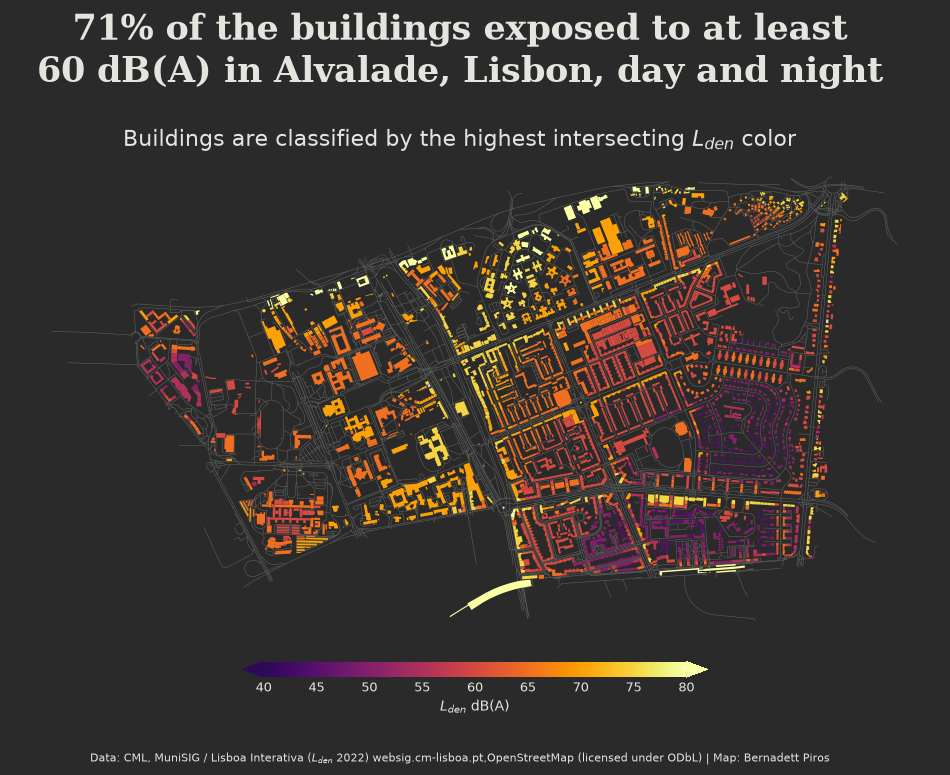

In [37]:
fig, ax = plt.subplots(figsize=(12, 8), facecolor="#292A29")

# Streets
streets.plot(ax=ax, color="#666866", lw=0.35, zorder=1)

# Use cmap from 0.1 to 1.0
cmap = LinearSegmentedColormap.from_list("inferno_custom", plt.cm.inferno(np.linspace(0.15, 1, 256)))

# Buildings
buildings_footprints.plot(ax=ax, column="Lden", cmap=cmap, ec="none", lw=0,
                          zorder=2, legend=True, legend_kwds={
                              "label": "$L_{den}$ dB(A)",
                              "orientation": "horizontal",
                              "shrink": 0.5,
                              "pad": 0.03,
                              "aspect": 30,
                              "extend": "both"},
                               missing_kwds={"color": "lightgrey"})

# Colorbar
cax = fig.axes[-1]

# Remove cbar outline
for spine in cax.spines.values():
    spine.set_visible(False)

# Cbar textcolor and size
cax.xaxis.label.set_color("#E5E5E0")
cax.xaxis.label.set_fontsize(10)

# Tick labels and tick marks 
cax.tick_params(axis="x", colors="#E5E5E0", labelsize=9, length=0)

ax.set_facecolor("#292A29")
ax.set_aspect("equal")
ax.axis("off")

# Title
fig.text(0.5, 0.95, 
         f"{percentage:.0f}% of the buildings exposed to at least\n60 dB(A) in Alvalade, Lisbon, day and night",         
         size=25, weight="bold", fontfamily="serif", color="#E5E5E0", ha="center")

# Subtitle
fig.text(0.5, 0.87, 
         r"Buildings are classified by the highest intersecting $L_{den}$ color",
         size=16, color="#E5E5E0", ha="center")

# Caption
fig.text(0.5, 0.1,
    r"Data: CML, MuniSIG / Lisboa Interativa ($L_{den}$ 2022) websig.cm-lisboa.pt,"
    f"OpenStreetMap (licensed under ODbL) | Map: Bernadett Piros",
    fontsize=8, color="#E5E5E0", ha="center")

plt.show()

#fig.savefig("sound.png", bbox_inches="tight", pad_inches=0.2) 